# 07 · Baseline models for SOH regression

**Owner:** Samina (Step 2 of the final modelling plan)

This notebook sets the floor that every stronger model has to beat. It follows the shared **evaluation protocol**
(`docs/evaluation_protocol.md`, `src/evaluation.py`, walkthrough in notebook 05), so its numbers can be compared
directly with every other model in the project.

| Baseline | Why we run it |
|---|---|
| Mean SOH of the training cells | The floor every model must beat |
| One feature: `cum_EFC` or `days_since_start` | Shows how much "time used" alone explains |
| Multiple linear regression (MLR) on the pruned main inputs | Interpretable reference |
| Ridge, Lasso, ElasticNet | Regularised linear models for the correlated feature blocks |

At the end we report the linear coefficients and their signs. Higher resistance and more usage should both
push SOH down, so negative signs are a quick physics sanity check.

**What the protocol fixes for us (no choices are made in this notebook)**
* Data: the 306 labelled rows (25 °C reference tests with SOH), 15 cells, 14 profiles — `ev.load_labelled()`.
* Inputs: the 42 numeric main inputs plus `schedule` — `ev.main_features()`. The comparison and leaky features
  (including `chg_CC_V0` and `chg_CV_time_s`, which are measured inside the test that defines SOH) are never inputs.
* Splits: leave-one-cell-out (**LOCO, headline**), leave-one-profile-out (LOPO), random 5-fold (seed 42, reference only).
* Pruning, 1–99 % clipping, imputation, scaling and one-hot encoding are fitted inside each training fold
  (`ev.make_pipeline`). Tuning is nested, with an inner grouped CV of the same kind as the outer split.
* The hyperparameter grids below are declared **before** any run and are not changed after seeing scores.
* The locked hold-out (`ev.holdout_check`) is **not** used here; it is reserved for final models only.

In [1]:
from pathlib import Path
import sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import explained_variance_score, mean_absolute_percentage_error, median_absolute_error
from sklearn.model_selection import GridSearchCV, GroupKFold

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import src.evaluation as ev
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)

OUT = ROOT / "results" / "baselines"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

df = ev.load_labelled()
NUM, CAT = ev.main_features()
print(f"{len(df)} labelled rows | {df.cell_id.nunique()} cells | {df.profile.nunique()} profiles")
print(f"main inputs: {len(NUM)} numeric + {CAT}")
assert "chg_CC_V0" not in NUM and "chg_CV_time_s" not in NUM

306 labelled rows | 15 cells | 14 profiles
main inputs: 42 numeric + ['schedule']


## 1. Baselines and their pre-declared grids

The single-feature models use only their one column (no `schedule`). All other models use the full main inputs.

In [2]:
# (spec, numeric inputs, categorical inputs) — grids fixed here, before any outer-fold score is seen.
BASELINES = [
    (ev.ModelSpec("Mean SOH (training cells)", DummyRegressor(strategy="mean"), family="baseline"), NUM, CAT),
    (ev.ModelSpec("One feature: cum_EFC", LinearRegression(), family="baseline"), ["cum_EFC"], []),
    (ev.ModelSpec("One feature: days_since_start", LinearRegression(), family="baseline"), ["days_since_start"], []),
    (ev.ModelSpec("MLR (pruned main set)", LinearRegression(), family="linear"), NUM, CAT),
    (ev.ModelSpec("Ridge (tuned)", Ridge(), {"alpha": list(np.logspace(-3, 3, 13))}, family="linear"), NUM, CAT),
    (ev.ModelSpec("Lasso (tuned)", Lasso(max_iter=50_000), {"alpha": list(np.logspace(-3, 1, 9))},
                  family="linear"), NUM, CAT),
    (ev.ModelSpec("ElasticNet (tuned)", ElasticNet(max_iter=50_000),
                  {"alpha": list(np.logspace(-3, 1, 9)), "l1_ratio": [0.2, 0.5, 0.8]}, family="linear"), NUM, CAT),
]
SCHEMES = ["LOCO", "LOPO", "Random 5-fold"]
MODELS = [s.name for s, _, _ in BASELINES]
INPUTS = {s.name: (num, cat) for s, num, cat in BASELINES}
SPECS = {s.name: s for s, _, _ in BASELINES}

## 2. Run every baseline on the three splits

In [3]:
results = {}
for spec, num, cat in BASELINES:
    for scheme in SCHEMES:
        results[(spec.name, scheme)] = ev.run_cv(df, spec, scheme, numeric=num, categorical=cat, verbose=False)
    print("done:", spec.name)
R = list(results.values())

done: Mean SOH (training cells)
done: One feature: cum_EFC
done: One feature: days_since_start
done: MLR (pruned main set)
done: Ridge (tuned)
done: Lasso (tuned)
done: ElasticNet (tuned)


In [4]:
def extra_metrics(oof):
    y, p = oof.y_true, oof.y_pred
    return dict(MedAE=median_absolute_error(y, p), ExplainedVar=explained_variance_score(y, p),
                MAPE_pct=100 * mean_absolute_percentage_error(y, p))

rows = []
for (name, scheme), r in results.items():
    f = r.folds
    rows.append(r.metrics | extra_metrics(r.oof) | dict(
        n_folds=len(f), fold_MAE_mean=f.MAE.mean(), fold_MAE_std=f.MAE.std(),
        worst_fold_MAE=f.MAE.max(), worst_fold=f.loc[f.MAE.idxmax(), "held_out"]))
metrics = pd.DataFrame(rows)
metrics["model"] = pd.Categorical(metrics.model, MODELS)
metrics["scheme"] = pd.Categorical(metrics.scheme, SCHEMES)
metrics = metrics.sort_values(["scheme", "model"]).reset_index(drop=True)
cols = ["model", "scheme", "n", "n_folds", "MAE", "RMSE", "R2", "MaxAE", "MedAE", "ExplainedVar", "MAPE_pct",
        "fold_MAE_mean", "fold_MAE_std", "worst_fold_MAE", "worst_fold"]
metrics = metrics[cols]

per_fold = pd.concat([r.folds for r in R], ignore_index=True)
oof_all = pd.concat([r.oof for r in R], ignore_index=True)
metrics.to_csv(OUT / "metrics_baselines.csv", index=False)
per_fold.to_csv(OUT / "per_fold_baselines.csv", index=False)
oof_all.to_csv(OUT / "oof_baselines.csv", index=False)

print("MAE (SOH percentage points, pooled out-of-fold) — lower is better. LOCO is the headline.")
display(metrics.pivot_table(index="model", columns="scheme", values="MAE", observed=True).round(2))
print("R² — higher is better")
display(metrics.pivot_table(index="model", columns="scheme", values="R2", observed=True).round(3))

MAE (SOH percentage points, pooled out-of-fold) — lower is better. LOCO is the headline.


scheme,LOCO,LOPO,Random 5-fold
model,,,
Mean SOH (training cells),8.18,8.24,7.89
One feature: cum_EFC,8.47,9.50,7.53
One feature: days_since_start,7.26,7.33,6.87
MLR (pruned main set),5.85,6.24,2.85
Ridge (tuned),4.76,4.89,2.79
Lasso (tuned),4.51,4.90,2.77
ElasticNet (tuned),4.25,4.45,2.79


R² — higher is better


scheme,LOCO,LOPO,Random 5-fold
model,,,
Mean SOH (training cells),-0.061,-0.067,-0.008
One feature: cum_EFC,-0.162,-0.522,0.069
One feature: days_since_start,0.126,0.117,0.199
MLR (pruned main set),0.406,0.370,0.833
Ridge (tuned),0.528,0.516,0.835
Lasso (tuned),0.497,0.478,0.827
ElasticNet (tuned),0.593,0.542,0.824


In [5]:
display(metrics.round(3))

,model,scheme,n,n_folds,MAE,RMSE,R2,MaxAE,MedAE,ExplainedVar,MAPE_pct,fold_MAE_mean,fold_MAE_std,worst_fold_MAE,worst_fold
0,Mean SOH (training cells),LOCO,306,15,8.177,11.432,-0.061,55.655,6.449,-0.061,11.034,8.960,5.459,21.232,2_076
1,One feature: cum_EFC,LOCO,306,15,8.468,11.968,-0.162,59.494,6.442,-0.162,11.394,9.326,6.154,21.489,2_076
2,One feature: days_since_start,LOCO,306,15,7.260,10.380,0.126,53.233,4.577,0.126,9.844,8.271,6.237,25.124,2_076
3,MLR (pruned main set),LOCO,306,15,5.848,8.552,0.406,45.762,4.285,0.417,7.566,6.723,5.621,21.634,2_076
4,Ridge (tuned),LOCO,306,15,4.761,7.629,0.528,49.881,2.973,0.528,6.501,5.149,3.663,12.267,2_095
5,Lasso (tuned),LOCO,306,15,4.515,7.875,0.497,57.582,2.299,0.498,6.410,5.073,4.595,14.379,2_095
6,ElasticNet (tuned),LOCO,306,15,4.248,7.083,0.593,51.890,2.450,0.593,5.949,4.694,3.773,12.361,2_095
7,Mean SOH (training cells),LOPO,306,14,8.236,11.464,-0.067,55.655,6.522,-0.067,11.097,9.219,5.567,21.232,L223
8,One feature: cum_EFC,LOPO,306,14,9.504,13.694,-0.522,59.494,6.413,-0.509,12.520,9.561,6.966,21.489,L223
9,One feature: days_since_start,LOPO,306,14,7.328,10.431,0.117,53.233,4.693,0.117,9.918,8.463,6.425,25.124,L223


### Consistency checks against notebook 05

* The mean baseline must match `results/evaluation_protocol/reference_mean_baseline.csv` (same rows, same folds).
* Our tuned Ridge should land close to the protocol's Ridge smoke test (LOCO ≈ 4.76, LOPO ≈ 4.89, random ≈ 2.79).
  It will not be identical because our alpha grid is wider, but a large gap would mean something differs.

In [6]:
ref = pd.read_csv(ROOT / "results" / "evaluation_protocol" / "reference_mean_baseline.csv").set_index("scheme")
ours = metrics[metrics.model == "Mean SOH (training cells)"].set_index("scheme")
chk = pd.DataFrame({"reference MAE": ref.MAE, "this notebook": ours.MAE.astype(float).round(3)}).loc[SCHEMES]
display(chk)
assert np.allclose(chk["reference MAE"], chk["this notebook"], atol=1e-3), "mean baseline does not match notebook 05"
print("OK: the mean baseline matches the protocol reference on every split.")

ridge = metrics[metrics.model == "Ridge (tuned)"].set_index("scheme").MAE.astype(float)
display(pd.DataFrame({"protocol smoke test": pd.Series({"LOCO": 4.76, "LOPO": 4.89, "Random 5-fold": 2.79}),
                      "this notebook": ridge.round(2)}).loc[SCHEMES])

,reference MAE,this notebook
scheme,,
LOCO,8.177,8.177
LOPO,8.236,8.236
Random 5-fold,7.894,7.894


OK: the mean baseline matches the protocol reference on every split.


,protocol smoke test,this notebook
LOCO,4.76,4.76
LOPO,4.89,4.89
Random 5-fold,2.79,2.79


## 3. Are the differences real? Paired fold-by-fold comparison (LOCO)

Following protocol rule 7, a lower pooled MAE only counts if it holds across folds. Each row compares two models
on the same 15 LOCO folds with a Wilcoxon signed-rank test. A negative `mean_diff` means model **a** is better.

In [7]:
pairs = [(m, "Mean SOH (training cells)") for m in MODELS[1:]] + [
    ("Ridge (tuned)", "MLR (pruned main set)"), ("Lasso (tuned)", "Ridge (tuned)"),
    ("ElasticNet (tuned)", "Ridge (tuned)")]
paired = pd.DataFrame([ev.paired_comparison(results[(a, "LOCO")], results[(b, "LOCO")]) for a, b in pairs])
paired.to_csv(OUT / "paired_comparison_loco.csv", index=False)
display(paired.round(4))

gap = ev.generalization_gap(R).reindex(MODELS)
gap.to_csv(OUT / "generalization_gap.csv")
print("Generalization gap (grouped MAE minus random MAE): how optimistic a random split is")
display(gap.round(2))

,a,b,scheme,n_folds,mean_diff,a_wins,b_wins,wilcoxon_p
0,One feature: cum_EFC,Mean SOH (training cells),LOCO,15,0.3657,11,4,0.3591
1,One feature: days_since_start,Mean SOH (training cells),LOCO,15,-0.6890,7,8,0.3894
2,MLR (pruned main set),Mean SOH (training cells),LOCO,15,-2.2368,11,4,0.0554
3,Ridge (tuned),Mean SOH (training cells),LOCO,15,-3.8104,13,2,0.0054
4,Lasso (tuned),Mean SOH (training cells),LOCO,15,-3.8866,14,1,0.0043
5,ElasticNet (tuned),Mean SOH (training cells),LOCO,15,-4.2654,14,1,0.0020
6,Ridge (tuned),MLR (pruned main set),LOCO,15,-1.5737,9,6,0.1354
7,Lasso (tuned),Ridge (tuned),LOCO,15,-0.0762,9,6,0.4887
8,ElasticNet (tuned),Ridge (tuned),LOCO,15,-0.4549,10,5,0.0256


Generalization gap (grouped MAE minus random MAE): how optimistic a random split is


scheme,LOCO,LOPO,Random 5-fold,gap LOCO - random,gap LOPO - random
model,,,,,
Mean SOH (training cells),8.18,8.24,7.89,0.28,0.34
One feature: cum_EFC,8.47,9.50,7.53,0.94,1.98
One feature: days_since_start,7.26,7.33,6.87,0.39,0.46
MLR (pruned main set),5.85,6.24,2.85,3.00,3.39
Ridge (tuned),4.76,4.89,2.79,1.97,2.10
Lasso (tuned),4.51,4.90,2.77,1.74,2.13
ElasticNet (tuned),4.25,4.45,2.79,1.45,1.66


## 4. Where does the error come from? (LOCO breakdowns)

Per protocol rule 6: MAE per held-out cell, per health class (<80, 80–90, ≥90) and for interpolation vs
extrapolation cells. Shown for the mean baseline and the best linear model.

In [8]:
loco = metrics[metrics.scheme == "LOCO"].set_index("model").MAE.astype(float)
best_linear = loco.loc[["MLR (pruned main set)", "Ridge (tuned)", "Lasso (tuned)", "ElasticNet (tuned)"]].idxmin()
print("best linear model on LOCO:", best_linear)

bd = {}
for by in ["cell_id", "health_class", "regime"]:
    t = pd.concat([ev.breakdown(results[(m, "LOCO")].oof, by).assign(model=m)
                   for m in ["Mean SOH (training cells)", best_linear]])
    bd[by] = t
    t.to_csv(OUT / f"breakdown_loco_by_{by}.csv", index=False)
    display(t.pivot_table(index=by, columns="model", values="MAE", observed=True)
             .join(t.groupby(by, observed=True).n.first()).round(2))

best linear model on LOCO: ElasticNet (tuned)


,ElasticNet (tuned),Mean SOH (training cells),n
cell_id,,,
2_009,0.91,5.18,21
2_010,2.49,6.35,21
2_012,7.24,18.47,22
2_027,1.73,8.01,22
2_030,3.42,5.50,22
2_033,6.98,6.99,22
2_058,2.35,4.58,22
2_067,5.00,10.43,21
2_076,10.49,21.23,6


,ElasticNet (tuned),Mean SOH (training cells),n
health_class,,,
Degraded (80-90),2.52,2.40,66
EOL risk (<80),10.22,21.09,53
Healthy (>=90),3.16,6.55,187


,ElasticNet (tuned),Mean SOH (training cells),n
regime,,,
extrapolation,9.66,13.87,66
interpolation,2.54,6.25,219
unclassified,5.00,10.43,21


## 5. Figure: MAE of each baseline on the three splits

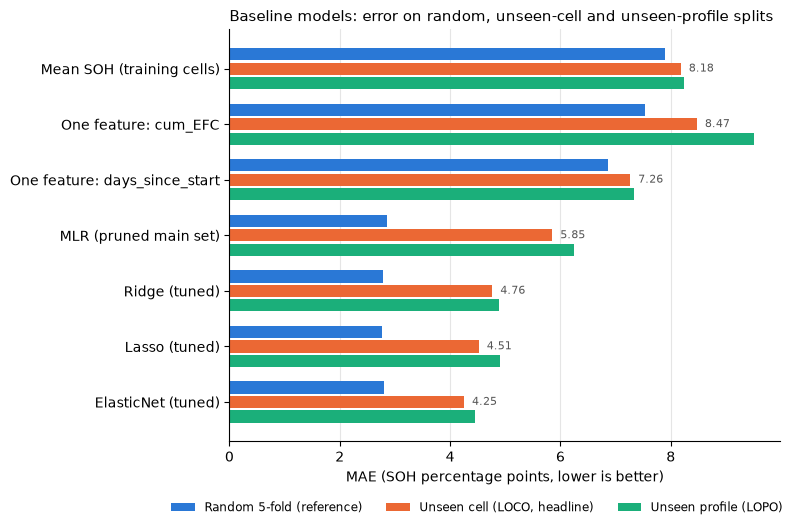

In [9]:
# Categorical slots 1–3 of the shared palette, in fixed order, one per split.
COLORS = {"LOCO": "#eb6834", "LOPO": "#1baf7a", "Random 5-fold": "#2a78d6"}
LABELS = {"LOCO": "Unseen cell (LOCO, headline)", "LOPO": "Unseen profile (LOPO)",
          "Random 5-fold": "Random 5-fold (reference)"}
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

piv = metrics.pivot_table(index="model", columns="scheme", values="MAE", observed=True).loc[MODELS[::-1]]
fig, ax = plt.subplots(figsize=(8, 5.4))
h = 0.26
for i, s in enumerate(["Random 5-fold", "LOCO", "LOPO"]):
    ax.barh(np.arange(len(piv)) + (1 - i) * h, piv[s], height=h - 0.04, color=COLORS[s], label=LABELS[s])
for i, name in enumerate(piv.index):                      # one direct label per model: the headline LOCO MAE
    v = piv.loc[name, "LOCO"]
    ax.text(v + 0.15, i, f"{v:.2f}", va="center", fontsize=8, color="#555")
ax.set_yticks(np.arange(len(piv)), piv.index)
ax.set_xlabel("MAE (SOH percentage points, lower is better)")
ax.xaxis.grid(True, color="#e5e5e5"); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.45, -0.12), ncol=3, fontsize=8.5)
ax.set_title("Baseline models: error on random, unseen-cell and unseen-profile splits", loc="left", fontsize=11)
fig.tight_layout(); fig.savefig(FIG / "baseline_mae_by_split.png", dpi=200); plt.show()

## 6. Linear coefficients and the physics sanity check

To read the signs we fit each linear model once on **all** 306 rows, tuning with a by-cell `GroupKFold`.
This fit is for interpretation only; every score above comes from held-out folds. Inputs are standardised, so a
coefficient is the change in SOH (percentage points) for a one-standard-deviation increase in that feature.

Expected sign:
* **Usage history** (`days_since_start`, `cum_*`, `rtp_index`): more use → lower SOH → **negative**.
* **Internal resistance** (`R_*`, excluding the pulse-count columns `R_*_n`): higher resistance → lower SOH → **negative**.

We also check **sign stability** across the 15 LOCO folds, refitting each fold with the alpha its inner CV chose.

In [10]:
USAGE = [c for c in NUM if c.startswith("cum_") or c in ("days_since_start", "rtp_index")]
RESIST = [c for c in NUM if c.startswith("R_") and not c.endswith("_n")]
KIND = {**{c: "usage" for c in USAGE}, **{c: "resistance" for c in RESIST}}
LINEAR = ["One feature: cum_EFC", "One feature: days_since_start", "MLR (pruned main set)",
          "Ridge (tuned)", "Lasso (tuned)", "ElasticNet (tuned)"]

def coef_table(pipe):
    names = pipe.named_steps["prep"].get_feature_names_out()
    return pd.Series(pipe.named_steps["model"].coef_, index=names)

X_all, y_all = df, df[ev.TARGET].to_numpy(float)
coef_rows = []
for m in LINEAR:
    spec, (num, cat) = SPECS[m], INPUTS[m]
    pipe = ev.make_pipeline(spec.estimator, num, cat)
    Xc = df[list(num) + list(cat) + ["cell_id"]]
    if spec.param_grid:
        gs = GridSearchCV(pipe, {f"model__{k}": v for k, v in spec.param_grid.items()}, cv=GroupKFold(5),
                          scoring="neg_mean_absolute_error", n_jobs=-1).fit(Xc, y_all, groups=df.cell_id)
        pipe, settings = gs.best_estimator_, {k.removeprefix("model__"): v for k, v in gs.best_params_.items()}
    else:
        pipe, settings = pipe.fit(Xc, y_all), {}
    for f, c in coef_table(pipe).items():
        coef_rows.append(dict(model=m, settings=settings, feature=f, kind=KIND.get(f, "other"), std_coef=c))
coefs = pd.DataFrame(coef_rows)
coefs["expected"] = np.where(coefs.kind == "other", "", "negative")
coefs["sign_ok"] = np.select([coefs.kind == "other", coefs.std_coef < 0, coefs.std_coef == 0],
                             ["", "yes", "zeroed"], "NO")
coefs.to_csv(OUT / "coefficients_full_fit.csv", index=False)

print("Single-feature slopes (cleanest check, nothing else competes with the feature):")
display(coefs[coefs.model.str.startswith("One feature")][["model", "feature", "std_coef", "sign_ok"]].round(3))
print("Usage and resistance coefficients kept by the pruner in the multi-feature models:")
mf = coefs[(coefs.kind != "other") & ~coefs.model.str.startswith("One feature")]
display(mf.pivot_table(index=["kind", "feature"], columns="model", values="std_coef", observed=True).round(3))

Single-feature slopes (cleanest check, nothing else competes with the feature):


,model,feature,std_coef,sign_ok
0,One feature: cum_EFC,cum_EFC,-3.229,yes
1,One feature: days_since_start,days_since_start,-5.221,yes


Usage and resistance coefficients kept by the pruner in the multi-feature models:


model                         ElasticNet (tuned)  Lasso (tuned)  MLR (pruned main set)  Ridge (tuned)
kind       feature                                                                                   
resistance R_0p18C_10s_mean                0.000          0.011                  1.414         -1.514
           R_1p35C_inst_mean              -9.202         -9.893                -11.182         -6.284
usage      cum_chg_Ah                      0.000          0.000                  0.415         -0.066
           cum_lp_Tdays                    1.287          1.697                  2.375          0.800
           cum_lp_days                     1.201          1.097                  1.405          0.885
           days_since_start               -1.836         -1.601                 -2.434         -2.097

In [11]:
# Sign stability across the 15 LOCO folds (refit each fold with its own chosen settings)
stab_rows = []
folds = ev.outer_folds(df, "LOCO")
for m in ["MLR (pruned main set)", "Ridge (tuned)", "Lasso (tuned)", "ElasticNet (tuned)"]:
    spec, (num, cat) = SPECS[m], INPUTS[m]
    Xc = df[list(num) + list(cat) + ["cell_id"]]
    chosen = results[(m, "LOCO")].folds.set_index("fold").best_params
    for k, (tr, te) in enumerate(folds):
        est = spec.estimator.__class__(**{**spec.estimator.get_params(), **chosen[k]})
        pipe = ev.make_pipeline(est, num, cat).fit(Xc.iloc[tr], y_all[tr])
        for f, c in coef_table(pipe).items():
            if f in KIND:
                stab_rows.append(dict(model=m, kind=KIND[f], feature=f, fold=k, coef=c))
stab = pd.DataFrame(stab_rows)
stability = (stab.groupby(["model", "kind", "feature"])
                 .agg(folds_kept=("coef", "size"), share_negative=("coef", lambda s: (s < 0).mean()),
                      share_zero=("coef", lambda s: (s == 0).mean()), median_coef=("coef", "median"))
                 .reset_index())
stability["folds_kept"] = stability.folds_kept.astype(str) + f"/{len(folds)}"
stability.to_csv(OUT / "coefficient_sign_stability_loco.csv", index=False)
display(stability.round(3))

,model,kind,feature,folds_kept,share_negative,share_zero,median_coef
0,ElasticNet (tuned),resistance,R_0p18C_10s_mean,14/15,1.000,0.000,-1.899
1,ElasticNet (tuned),resistance,R_0p18C_inst_mean,2/15,1.000,0.000,-2.753
2,ElasticNet (tuned),resistance,R_1p13C_inst_mean,1/15,1.000,0.000,-6.096
3,ElasticNet (tuned),resistance,R_1p35C_10s_mean,1/15,1.000,0.000,-7.192
4,ElasticNet (tuned),resistance,R_1p35C_inst_mean,7/15,1.000,0.000,-6.043
5,ElasticNet (tuned),usage,cum_chg_Ah,15/15,0.133,0.867,-0.000
6,ElasticNet (tuned),usage,cum_lp_Tdays,15/15,0.000,0.867,-0.000
7,ElasticNet (tuned),usage,cum_lp_days,15/15,0.067,0.867,0.000
8,ElasticNet (tuned),usage,days_since_start,13/15,1.000,0.000,-0.623
9,ElasticNet (tuned),usage,rtp_index,2/15,1.000,0.000,-1.442


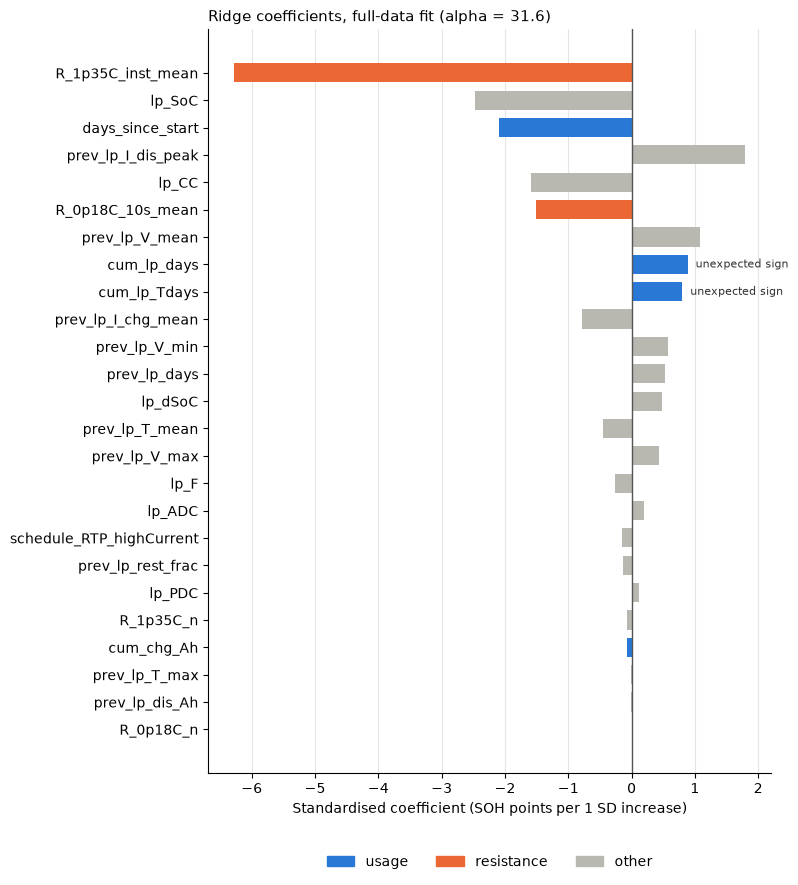

In [12]:
# Figure: Ridge standardised coefficients (full-data fit); usage and resistance features highlighted
r = coefs[coefs.model == "Ridge (tuned)"].copy()
r = r.reindex(r.std_coef.abs().sort_values().index)
col = {"usage": "#2a78d6", "resistance": "#eb6834", "other": "#b9b8b0"}
fig, ax = plt.subplots(figsize=(8, 0.3 * len(r) + 1.4))
ax.barh(r.feature, r.std_coef, color=[col[k] for k in r.kind], height=0.7)
ax.axvline(0, color="#555", lw=1)
for i, row in enumerate(r.itertuples()):
    if row.sign_ok == "NO":
        ax.text(row.std_coef, i, "  unexpected sign", va="center", ha="left", fontsize=8, color="#333")
ax.legend(handles=[Patch(color=col[k], label=k) for k in ("usage", "resistance", "other")],
          frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.07 - 0.6 / len(r)), ncol=3)
ax.set_xlabel("Standardised coefficient (SOH points per 1 SD increase)")
ax.xaxis.grid(True, color="#e5e5e5"); ax.set_axisbelow(True)
ax.set_title(f"Ridge coefficients, full-data fit (alpha = {r.settings.iloc[0]['alpha']:.3g})", loc="left",
             fontsize=11)
fig.tight_layout(); fig.savefig(FIG / "ridge_coefficients.png", dpi=200); plt.show()

## 7. Summary (generated from the numbers above)

In [13]:
m = metrics.set_index(["model", "scheme"]).MAE.astype(float)
floor = m[("Mean SOH (training cells)", "LOCO")]
pv = paired.set_index("a")
lines = [f"- Floor: mean SOH of the training cells, LOCO MAE {floor:.2f} SOH points."]
for name in MODELS[1:]:
    p = pv[(pv.index == name) & (pv.b == "Mean SOH (training cells)")].iloc[0]
    lines.append(f"- {name}: LOCO {m[(name, 'LOCO')]:.2f} | LOPO {m[(name, 'LOPO')]:.2f} | random "
                 f"{m[(name, 'Random 5-fold')]:.2f}; vs mean baseline: better in {p.a_wins}/{p.n_folds} folds, "
                 f"Wilcoxon p = {p.wilcoxon_p:.3g}.")
single = coefs[coefs.model.str.startswith("One feature")]
lines.append("- Single-feature slopes: " + "; ".join(f"{r.feature} {r.std_coef:+.2f} (negative as expected: {r.sign_ok})"
                                                       for r in single.itertuples()))
bad = mf[mf.sign_ok == "NO"]
lines.append("- Usage/resistance coefficients with an unexpected positive sign in the full-data fits: "
             + (", ".join(f"{r.feature} ({r.model})" for r in bad.itertuples()) if len(bad) else "none"))
print("\n".join(lines))

- Floor: mean SOH of the training cells, LOCO MAE 8.18 SOH points.
- One feature: cum_EFC: LOCO 8.47 | LOPO 9.50 | random 7.53; vs mean baseline: better in 11/15 folds, Wilcoxon p = 0.359.
- One feature: days_since_start: LOCO 7.26 | LOPO 7.33 | random 6.87; vs mean baseline: better in 7/15 folds, Wilcoxon p = 0.389.
- MLR (pruned main set): LOCO 5.85 | LOPO 6.24 | random 2.85; vs mean baseline: better in 11/15 folds, Wilcoxon p = 0.0554.
- Ridge (tuned): LOCO 4.76 | LOPO 4.89 | random 2.79; vs mean baseline: better in 13/15 folds, Wilcoxon p = 0.00537.
- Lasso (tuned): LOCO 4.51 | LOPO 4.90 | random 2.77; vs mean baseline: better in 14/15 folds, Wilcoxon p = 0.00427.
- ElasticNet (tuned): LOCO 4.25 | LOPO 4.45 | random 2.79; vs mean baseline: better in 14/15 folds, Wilcoxon p = 0.00201.
- Single-feature slopes: cum_EFC -3.23 (negative as expected: yes); days_since_start -5.22 (negative as expected: yes)
- Usage/resistance coefficients with an unexpected positive sign in the full-data 

**How to read the sign check.** In the single-feature models a positive slope would be a real red flag. In the
multi-feature models, a usage or resistance feature can still get a positive coefficient when it is correlated with
other kept features (for example the `cum_*` columns and `days_since_start`); the model then splits one effect
between them. Lasso tends to set such duplicates to zero. The sign-stability table shows whether an odd sign is
consistent across folds or only appears in a few.

**Result files** (all in `results/baselines/`): `metrics_baselines.csv`, `per_fold_baselines.csv`,
`oof_baselines.csv`, `paired_comparison_loco.csv`, `generalization_gap.csv`, `breakdown_loco_by_*.csv`,
`coefficients_full_fit.csv`, `coefficient_sign_stability_loco.csv`, and two figures in `figures/`.